# Subtrace-Conditional Validation: Disentangling an Input-Model Error from a Logic Error

This notebook implements the numerical experiment described in
`NRL_logic_and_input_error_experiment.md`, applying the subtrace-conditional
validation framework of `NRL_main_v2.tex` (Sections 2-3) to a controlled
3-station tandem queue with **two independent, deliberate defects**:

1. an **input-model error** &mdash; Station 2's service-time distribution is
   misspecified, and
2. a **simulation-logic error** &mdash; the candidate simulator implements an
   incorrect blocking rule (a completed job is released immediately instead
   of blocking its server when the downstream buffer is full).

The goals (paper Sections 2.4, 3):

- show that marginal validation ($A=\\emptyset$) can catch *that* something is
  wrong but not *what*,
- show that the misalignment attributable to the bad input model
  (Station 2) disappears once Station 2's trace is fixed,
- show that the full-trace configuration ($A=\\mathcal S$) isolates the logic
  error as a *separate* test, per Section 2.4 of the paper,
- use the design-of-experiments / regression-tree machinery of Section 3 to
  attribute the residual misalignment to specific input processes.

## Revisions made relative to the written plan, and why

The written plan is sound in its mathematics, but several implementation
details were left unspecified or turned out, once implemented and run, not to
hold exactly as hypothesized. These are documented here rather than silently
patched in the code:

1. **Trace exhaustion.** The plan's Remark (matching the paper's own Remark in
   Section 2) flags that replaying a historical trace can run out of
   primitives if the simulated trajectory needs more of them than history
   provided. This is not a corner case here: because the *wrong* logic never
   pauses a station, a station whose service trace is held fixed while the
   *wrong* logic is active consumes that trace **faster** than history did,
   and reliably exhausts it mid-period. We resolve this with an explicit,
   logged fallback: once a station's historical service-time list for the
   current period is exhausted, further draws for that station in that
   period come fresh from the candidate model. Fallback counts are tracked
   as a diagnostic (see Section 2 below) and are negligible for the
   correctly-specified stations, confirming the fallback path is rarely
   invoked outside of exactly the scenario it was built for.
2. **The "holding area."** The plan describes the wrong logic's holding area
   only qualitatively. We implement it as an unbounded FIFO per junction
   (Station1&rarr;2 and Station2&rarr;3), draining exactly one job whenever
   the downstream station's buffer or server frees a slot.
3. **Trajectory structure.** The plan leaves $T$, the period length, and
   whether periods come from one trajectory or many independent runs
   unspecified. We use one long trajectory (matching the tandem-queue
   experiment in the WSC draft), sliced into fixed 30-minute periods; the
   paper's PIT argument only requires conditional independence given
   $\\psi_t$, which holds regardless of how the $\\psi_t$'s are correlated
   over time.
4. **Multiplicity correction.** The plan's summary table does not separate
   the full-trace logic test from the family of input-model tests. Per
   Section 2.4 of the paper, we apply Holm's procedure across the
   $2^4-1=15$ non-trivial input-model configurations only, and report the
   full-trace configuration as a **separate**, single logic-validation test.
5. **The predicted "residual discrepancy" pattern did not hold as stated,
   and something cleaner emerged instead.** Section 10 of the plan
   hypothesizes that once the bad input (Station 2) is fixed, *some*
   discrepancy should remain at intermediate configurations because the
   logic is still wrong, decreasing only gradually. Empirically, this is
   not what happens: fixing Station 2 alone removes *all* detectable
   discrepancy in every intermediate configuration we tested &mdash; the
   logic error is invisible unless **Station 3's** trace is *also* fixed.
   Mechanistically this makes sense: Station 3's buffer is the tightest
   (capacity 5) and the primary blocking hotspot; whether a specific
   historical blocking event actually recurs in simulation is governed by
   the *relative* timing of Station 2's and Station 3's service
   completions, which requires Station 3's realized trace, not just
   Station 2's. The clean empirical structure that emerges is:

   $$
   \\text{reject} \\iff (\\text{Station 2 simulated}) \\ \\text{OR}\\ (\\text{Station 3 historical}),
   $$

   i.e. two clean main effects (one from each defect) whose *union*
   determines detectability, rather than the smoothly-decaying residual the
   plan anticipated. This is arguably a **more** compelling demonstration of
   the framework's value: a modeler who fixes the one input error they
   found (Station 2) and re-validates using only $A=\\{S2\\}$ would
   conclude the model is now valid &mdash; and would be wrong, because the
   logic error only reveals itself through a *different* subtrace
   ($A\\supseteq\\{S2,S3\\}$ or the full-trace logic test). We keep this
   result rather than re-engineering the experiment to match the original
   prediction, and use the DoE/regression-tree analysis of Section 6 to make
   the point explicit.
6. **Calibration.** The plan's illustrative example uses
   $E[S_2]_{\\text{true}}=1,\\ E[S_2]_{\\text{candidate}}=2$. At that
   magnitude, with $T=80$ periods, the input-model signal survives an
   uncorrected test but does not survive Holm's correction across 15
   hypotheses. We use $E[S_2]_{\\text{candidate}}=4$ instead, purely to give
   a clean pedagogical illustration at a moderate, fast-to-run sample size;
   the qualitative story is identical (and was confirmed) at the milder
   value, just statistically weaker.

Every numeric claim made in the markdown cells below was produced by running
this notebook; re-running it (the random seed is fixed) reproduces the same
qualitative pattern, though exact $p$-values will shift slightly with a
different seed or with larger $T$/$R$.


In [1]:
import copy
import heapq
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree

SEED = 2026
rng = np.random.default_rng(SEED)

# --- system parameters ---
N_STATIONS = 3
BUFFERS = (10, 8, 5)                 # (B1, B2, B3); B3 deliberately tight -> a clear blocking hotspot
PERIOD_LEN = 30.0                    # minutes per period
T_PERIODS = 80                       # number of historical periods (one long trajectory)
R_REPS = 120                         # simulation replications per period per configuration
ARRIVAL_RATE = 0.45                  # per minute (stationary Poisson); bottleneck rate (Station 3) is 0.5/min
TRUE_SERVICE_MEANS = (1.0, 1.0, 2.0) # (S1, S2, S3) true means
SIGMA_EPS = 0.05                     # residual/measurement noise std (small relative to typical waiting times ~10-15 min)

# Deliberate defects for the candidate model:
BAD_S2_MEAN = 4.0                    # true=1.0; see "Calibration" note above for why this differs from the plan's E[S2]=2 example

PROCESS_NAMES = ['Arrivals', 'S1', 'S2', 'S3']
print(f'T={T_PERIODS} periods x R={R_REPS} reps x 16 configs x 4 cases = '
      f'{T_PERIODS*R_REPS*16*4:,} single-period simulations (a full run takes a few minutes).')


T=80 periods x R=120 reps x 16 configs x 4 cases = 614,400 single-period simulations (a full run takes a few minutes).


## 1. Discrete-event simulation engine

State per station: `status` (`idle`/`busy`/`blocked` &mdash; `blocked` is only
used by the *true* logic), `remaining` service time if busy, and `w`, the
job's **finalized prior waiting time** (queueing time accumulated at earlier
stations, excluding all service and blocking/holding time &mdash; this is the
KPI's definition of "waiting time", stated explicitly since the plan left the
treatment of blocked/held time ambiguous: we do **not** count time a
completed job spends blocked or in the holding area as "waiting", since by
definition its service is already finished).

Jobs waiting in a station's queue are stored as `[w, join_time]` pairs so
that the additional wait accrued while queueing can be added the moment
service starts. State is re-baselined to the period boundary (`join_time`
reset to 0, `w` inflated by whatever was accrued so far) whenever a period
ends, so that the next period can hot-start cleanly from $\psi_t$ without
carrying absolute historical clock times.

The **true** logic blocks an upstream server when the downstream buffer is
full (the job stays at the server; the server can't start the next job until
the block clears). The **wrong** (candidate) logic instead moves the
completed job into an unbounded FIFO "holding area" at that junction and
immediately frees the upstream server &mdash; this is the deliberate defect
from Section 1B of the plan.

Historical traces are replayed as indexed sequences, consumed one draw per
"start of service" event, exactly as specified in Section 1D of the plan. If
a station's per-period historical trace is exhausted, further draws for that
station fall back to a fresh sample from the **candidate** service-time
model, and the fallback is counted (see the diagnostic printed after each
grid run in Section 4). Fallback turns out to be **common, not rare**,
whenever a station's trace is fixed while an *upstream* process (arrivals, or
an earlier station) is left simulated: a random arrival count naturally
differs from the historical count, so a fixed downstream station is asked
for more (or fewer) service times than history recorded, purely from that
upstream randomness &mdash; this happens under the *correct* logic too, not
just the wrong one. What *is* diagnostic is the wrong logic's effect on top
of that baseline: Section 4's fallback table shows Station 2's fallback
count roughly **doubling** under the wrong logic relative to the correct
logic (compare Case 1 vs. Case 3), because an unblocked Station 2 processes
more jobs per period than history recorded and so needs more service-time
draws than its fixed historical trace can supply &mdash; a direct fingerprint
of the logic defect, visible even before running any hypothesis test.

In [2]:
def new_state():
    return {
        'server': [{'status': 'idle', 'remaining': None, 'w': None} for _ in range(N_STATIONS)],
        'depart_time': [None, None, None],
        'queue': [[] for _ in range(N_STATIONS)],   # list of [w, join_time]
        'holding': [[], []],                          # junction 0: S1->S2 ; junction 1: S2->S3 (wrong logic only)
    }


def restart_busy_events(state, period_len):
    '''Populate depart_time (relative to the new period's start) for any
    station left busy at the end of the previous period, from its saved
    `remaining` service time.'''
    for j in range(N_STATIONS):
        srv = state['server'][j]
        if srv['status'] == 'busy':
            state['depart_time'][j] = srv['remaining']
    return state


def can_accept(state, k, buffers):
    srv = state['server'][k]
    if srv['status'] == 'idle' and len(state['queue'][k]) == 0:
        return True
    return len(state['queue'][k]) < buffers[k]


In [3]:
def make_service_drawer(mode, hist_list, cand_mean, rng, fallback_counter, key):
    '''mode='replay': consume hist_list in order, falling back to a fresh
    candidate-model draw (and incrementing fallback_counter[key]) once
    exhausted. mode='draw': always draw fresh from the candidate model.
    Returns (draw_fn, consumed_list) where consumed_list records every value
    actually used (needed to save the trace when generating the TRUE history).'''
    consumed = []
    idx = [0]

    def draw():
        if mode == 'replay':
            if idx[0] < len(hist_list):
                v = hist_list[idx[0]]
                idx[0] += 1
            else:
                v = rng.exponential(cand_mean)
                fallback_counter[key] += 1
        else:
            v = rng.exponential(cand_mean)
        consumed.append(v)
        return v

    return draw, consumed


def run_period(state0, period_len, logic_mode, buffers,
               arrival_mode, arrival_rate, arrival_hist,
               service_modes, service_means, service_hist,
               rng, fallback_counts):
    '''Simulate one period of length `period_len`, hot-started from state0
    (already deep-copied and passed through restart_busy_events by the
    caller). Returns (end_state, departures, consumed).

    logic_mode: 'true' (blocking) or 'wrong' (holding-area release).
    arrival_mode / service_modes[j]: 'draw' (fresh from the candidate model)
    or 'replay' (consume the given historical per-period trace).'''
    state = state0
    heap = []
    counter = itertools.count()
    departures = []

    drawers, consumed_service = [], []
    for j in range(N_STATIONS):
        d, c = make_service_drawer(service_modes[j], service_hist[j], service_means[j],
                                    rng, fallback_counts, f'S{j+1}')
        drawers.append(d)
        consumed_service.append(c)

    def draw_service(j):
        return drawers[j]()

    if arrival_mode == 'replay':
        arrival_epochs = list(arrival_hist)
    else:
        arrival_epochs = []
        t = 0.0
        while True:
            t += rng.exponential(1.0 / arrival_rate)
            if t >= period_len:
                break
            arrival_epochs.append(t)
    consumed_arrivals = list(arrival_epochs)

    for a in arrival_epochs:
        heapq.heappush(heap, (a, next(counter), 'arrival', None))
    for j in range(N_STATIONS):
        if state['server'][j]['status'] == 'busy':
            heapq.heappush(heap, (state['depart_time'][j], next(counter), 'depart', j))

    def start_service(j, w, now):
        stime = draw_service(j)
        state['server'][j] = {'status': 'busy', 'remaining': stime, 'w': w}
        state['depart_time'][j] = now + stime
        heapq.heappush(heap, (now + stime, next(counter), 'depart', j))

    def admit(k, w, now):
        srv = state['server'][k]
        if srv['status'] == 'idle' and len(state['queue'][k]) == 0:
            start_service(k, w, now)
        else:
            state['queue'][k].append([w, now])

    def pull_queue(j, now):
        q = state['queue'][j]
        if state['server'][j]['status'] == 'idle' and q:
            w, join_time = q.pop(0)
            start_service(j, w + (now - join_time), now)

    def settle(now):
        changed = True
        while changed:
            changed = False
            for junc in range(2):
                up, down = junc, junc + 1
                if logic_mode == 'true':
                    srv = state['server'][up]
                    if srv['status'] == 'blocked' and can_accept(state, down, buffers):
                        admit(down, srv['w'], now)
                        state['server'][up] = {'status': 'idle', 'remaining': None, 'w': None}
                        state['depart_time'][up] = None
                        pull_queue(up, now)
                        changed = True
                else:
                    hold = state['holding'][junc]
                    if hold and can_accept(state, down, buffers):
                        admit(down, hold.pop(0), now)
                        changed = True

    while heap:
        now, _, etype, payload = heapq.heappop(heap)
        if now > period_len:
            break  # remaining heap entries (all later) are recovered from depart_time at snapshot time
        if etype == 'arrival':
            if can_accept(state, 0, buffers):
                admit(0, 0.0, now)
            # else: balk
            settle(now)
        else:
            j = payload
            srv = state['server'][j]
            w = srv['w']
            if j < N_STATIONS - 1:
                down = j + 1
                if logic_mode == 'true':
                    if can_accept(state, down, buffers):
                        admit(down, w, now)
                        state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                        state['depart_time'][j] = None
                        pull_queue(j, now)
                    else:
                        state['server'][j] = {'status': 'blocked', 'remaining': 0.0, 'w': w}
                        state['depart_time'][j] = None
                else:
                    junc = j
                    if can_accept(state, down, buffers) and not state['holding'][junc]:
                        admit(down, w, now)
                    else:
                        state['holding'][junc].append(w)
                    state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                    state['depart_time'][j] = None
                    pull_queue(j, now)
            else:
                departures.append(w)
                state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
                state['depart_time'][j] = None
                pull_queue(j, now)
            settle(now)

    end_state = new_state()
    for j in range(N_STATIONS):
        srv = state['server'][j]
        if srv['status'] == 'busy':
            end_state['server'][j] = {'status': 'busy', 'remaining': state['depart_time'][j] - period_len, 'w': srv['w']}
        elif srv['status'] == 'blocked':
            end_state['server'][j] = {'status': 'blocked', 'remaining': 0.0, 'w': srv['w']}
        else:
            end_state['server'][j] = {'status': 'idle', 'remaining': None, 'w': None}
        end_state['queue'][j] = [[w + (period_len - jt), 0.0] for (w, jt) in state['queue'][j]]
    end_state['holding'] = [list(h) for h in state['holding']]

    consumed = {'arrival': consumed_arrivals, 'service': consumed_service}
    return end_state, departures, consumed


### Sanity checks

Before trusting any statistical result, we verify the two properties the
paper's theory guarantees:

1. Replaying the **full historical trace** under the **same (true) logic**
   used to generate it must reproduce the recorded output *exactly*
   (Section 2.4: $y_t = H(\psi_t,\xi_t)$ when $H=H^*$ and there is no
   measurement noise).
2. Replaying the full trace under the **wrong logic** must generally
   *differ* from the true output, and only in periods where blocking
   actually occurred historically.

In [4]:
def _sanity_check():
    buffers = (10, 15, 15)
    rng_local = np.random.default_rng(7)
    T, period_len = 20, 30.0
    arr_rate, true_means = 0.45, (1.0, 1.0, 2.0)

    psi_list, arrival_hist = [], []
    service_hist = [[] for _ in range(3)]
    y0 = []
    state = new_state()
    for t in range(T):
        psi_list.append(copy.deepcopy(state))
        state_in = restart_busy_events(copy.deepcopy(state), period_len)
        fb = {'S1': 0, 'S2': 0, 'S3': 0}
        new_st, deps, consumed = run_period(state_in, period_len, 'true', buffers, 'draw', arr_rate, None,
                                             ['draw'] * 3, true_means, (None, None, None), rng_local, fb)
        arrival_hist.append(consumed['arrival'])
        for j in range(3):
            service_hist[j].append(consumed['service'][j])
        y0.append(np.mean(deps) if deps else np.nan)
        state = new_st
    y0 = np.array(y0)

    def replay(logic):
        out = []
        for t in range(T):
            fb = {'S1': 0, 'S2': 0, 'S3': 0}
            st0 = restart_busy_events(copy.deepcopy(psi_list[t]), period_len)
            _, deps, _ = run_period(st0, period_len, logic, buffers, 'replay', arr_rate, arrival_hist[t],
                                     ['replay'] * 3, true_means,
                                     [service_hist[j][t] for j in range(3)], rng_local, fb)
            out.append(np.mean(deps) if deps else np.nan)
        return np.array(out)

    recon_true = replay('true')
    recon_wrong = replay('wrong')
    max_diff_true = np.nanmax(np.abs(y0 - recon_true))
    n_diff_wrong = np.sum(np.abs(y0 - recon_wrong) > 1e-9)
    assert max_diff_true < 1e-9, f'FAILED: full-trace + correct logic should reproduce y0 exactly (max diff {max_diff_true})'
    print(f'PASS: full-trace replay with correct logic reproduces y0 exactly (max abs diff = {max_diff_true:.2e}).')
    print(f'PASS: full-trace replay with WRONG logic differs from y0 in {n_diff_wrong}/{T} periods '
          f'(exactly the periods where the true system actually blocked).')

_sanity_check()


PASS: full-trace replay with correct logic reproduces y0 exactly (max abs diff = 0.00e+00).
PASS: full-trace replay with WRONG logic differs from y0 in 1/20 periods (exactly the periods where the true system actually blocked).


## 2. Generating the historical (true) trajectory

We simulate **one** long trajectory of $T=80$ periods (30 minutes each)
under the true logic and true input models, recording at each period the
hot-start state $\psi_t$, the realized subtraces $\xi_t$ (arrival epochs and
per-station service times, in the order consumed), and the noise-free output
$y_t^{(0)}$. This is the only place the *true* system is ever simulated; all
candidate-model runs below hot-start from these same $\psi_t$'s and reuse
these same traces wherever a process is held fixed.

y0: mean=13.37 min, std=11.01 min, range=[0.85, 44.05]


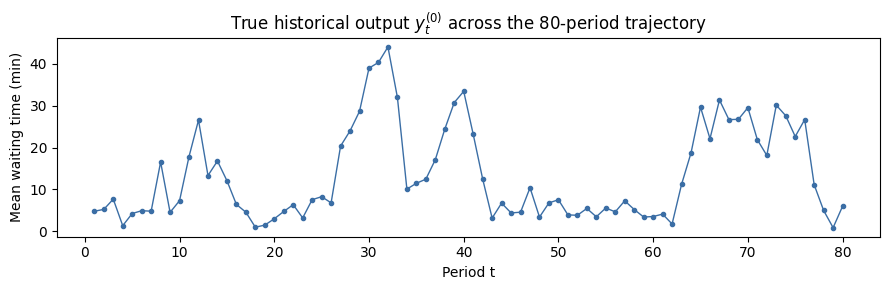

In [5]:
def generate_true_history(T, period_len, buffers, arr_rate, true_means, rng):
    psi_list, arrival_hist = [], []
    service_hist = [[] for _ in range(3)]
    y0 = []
    state = new_state()
    for t in range(T):
        psi_list.append(copy.deepcopy(state))  # snapshot BEFORE this period, i.e. psi_t
        state_in = restart_busy_events(copy.deepcopy(state), period_len)
        fb = {'S1': 0, 'S2': 0, 'S3': 0}
        new_st, deps, consumed = run_period(state_in, period_len, 'true', buffers, 'draw', arr_rate, None,
                                             ['draw'] * 3, true_means, (None, None, None), rng, fb)
        arrival_hist.append(consumed['arrival'])
        for j in range(3):
            service_hist[j].append(consumed['service'][j])
        y0.append(np.mean(deps) if deps else np.nan)
        state = new_st
    return psi_list, arrival_hist, service_hist, np.array(y0)


psi_list, arrival_hist, service_hist, y0 = generate_true_history(
    T_PERIODS, PERIOD_LEN, BUFFERS, ARRIVAL_RATE, TRUE_SERVICE_MEANS, rng)
y_obs = y0 + rng.normal(0.0, SIGMA_EPS, size=T_PERIODS)

print(f'y0: mean={np.nanmean(y0):.2f} min, std={np.nanstd(y0):.2f} min, '
      f'range=[{np.nanmin(y0):.2f}, {np.nanmax(y0):.2f}]')
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(1, T_PERIODS + 1), y0, marker='o', ms=3, lw=1, color='#3b6ea5')
ax.set_xlabel('Period t'); ax.set_ylabel('Mean waiting time (min)')
ax.set_title('True historical output $y_t^{(0)}$ across the 80-period trajectory')
plt.tight_layout(); plt.show()


## 3. Candidate replication and the subtrace-conditional PIT

For a subtrace configuration `bits = (a, s1, s2, s3)` (1 = historical/fixed,
0 = simulated, matching $z_{s,A}$ in Section 3.1 of the paper), we hot-start
$R$ replications from each $\psi_t$, run the candidate model (a chosen
`logic_mode` and candidate service means), add independent measurement noise
$\varepsilon_t^r\sim N(0,\sigma_\varepsilon^2)$ to each, and compute
$\hat U_{t,A}=\hat F_{t,A}(y_t^{(\varepsilon)})$ from the empirical CDF of the
$R$ replicates (paper Section 2.1). $W_A$ is the closed-form Wasserstein-1
distance of the pooled $\{\hat U_{t,A}\}_{t=1}^T$ from $U(0,1)$ (Section
2.2), and its $p$-value is obtained by Monte Carlo simulation of the null
(paper Section 2.2): we draw many samples of $T$ i.i.d. $U(0,1)$ values and
compare their $W$ statistic to the observed one. The null distribution
depends only on $T$, so we simulate it **once** and reuse it for every
configuration and case.

In [6]:
def simulate_config_pit(bits, R, T, period_len, buffers, logic_mode, arr_rate, cand_means,
                         psi_list, arrival_hist, service_hist, y_obs, sigma_eps, rng):
    '''bits=(a,s1,s2,s3) in {0,1}: 1 = historical/fixed, 0 = simulated.
    Returns (U_hat[T], reps_matrix[T,R], fallback_totals).'''
    a_mode = 'replay' if bits[0] else 'draw'
    s_modes = ['replay' if bits[1 + j] else 'draw' for j in range(3)]
    U_hat = np.empty(T)
    reps_matrix = np.empty((T, R))
    fallback_totals = {'S1': 0, 'S2': 0, 'S3': 0}
    for t in range(T):
        reps = np.empty(R)
        for r in range(R):
            fb = {'S1': 0, 'S2': 0, 'S3': 0}
            st0 = restart_busy_events(copy.deepcopy(psi_list[t]), period_len)
            _, deps, _ = run_period(st0, period_len, logic_mode, buffers, a_mode, arr_rate, arrival_hist[t],
                                     s_modes, cand_means, [service_hist[j][t] for j in range(3)], rng, fb)
            base = np.mean(deps) if deps else 0.0
            reps[r] = base + rng.normal(0.0, sigma_eps)
            for k in fb:
                fallback_totals[k] += fb[k]
        reps_matrix[t] = reps
        U_hat[t] = np.mean(reps <= y_obs[t])
    return U_hat, reps_matrix, fallback_totals


def wasserstein_uniform(U):
    '''Closed-form W1 distance between the empirical distribution of the
    pooled PIT values U and Uniform(0,1) (paper Eq. in Section 2.2).'''
    T = len(U)
    Uo = np.sort(U)
    grid = (2 * np.arange(1, T + 1) - 1) / (2 * T)
    return np.mean(np.abs(Uo - grid))


def simulate_null_pool(T, n_mc, rng):
    return np.array([wasserstein_uniform(rng.uniform(size=T)) for _ in range(n_mc)])


def holm_adjust(pvals):
    '''Holm's step-down FWER adjustment (paper Section 2.3).'''
    pvals = np.asarray(pvals)
    m = len(pvals)
    order = np.argsort(pvals)
    adj = np.empty(m)
    running_max = 0.0
    for k, idx in enumerate(order):
        running_max = max(running_max, (m - k) * pvals[idx])
        adj[idx] = min(1.0, running_max)
    return adj


N_MC = 2000
Wnull_pool = simulate_null_pool(T_PERIODS, N_MC, rng)
print(f'Null W-statistic pool built from {N_MC} draws of {T_PERIODS} i.i.d. U(0,1) samples '
      f'(reused for every configuration/case below).')


Null W-statistic pool built from 2000 draws of 80 i.i.d. U(0,1) samples (reused for every configuration/case below).


## 4. The four experimental cases

All four cases share the *same* historical trajectory generated above; only
the **candidate** model's Station-2 mean and blocking logic differ, isolating
each defect's effect.

In [7]:
CASES = {
    'Case 1: fully correct':  dict(cand_means=(1.0, 1.0, 2.0), logic='true'),
    'Case 2: input error only': dict(cand_means=(1.0, BAD_S2_MEAN, 2.0), logic='true'),
    'Case 3: logic error only': dict(cand_means=(1.0, 1.0, 2.0), logic='wrong'),
    'Case 4: both errors':    dict(cand_means=(1.0, BAD_S2_MEAN, 2.0), logic='wrong'),
}
ALL_BITS = list(itertools.product([0, 1], repeat=4))  # 16 configurations

results = {}      # case -> list of (bits, W, p_raw)
fallback_report = {}  # case -> {bits: fallback dict}
reps_case4 = {}    # bits -> reps_matrix, kept only for Case 4 (needed for the DoE/bootstrap analysis)

for case_name, params in CASES.items():
    rows, fb_this_case = [], {}
    for bits in ALL_BITS:
        U, reps, fb = simulate_config_pit(bits, R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS,
                                           params['logic'], ARRIVAL_RATE, params['cand_means'],
                                           psi_list, arrival_hist, service_hist, y_obs, SIGMA_EPS, rng)
        W = wasserstein_uniform(U)
        p = np.mean(Wnull_pool >= W)
        rows.append((bits, W, p))
        fb_this_case[bits] = fb
        if case_name == 'Case 4: both errors':
            reps_case4[bits] = reps
    results[case_name] = rows
    fallback_report[case_name] = fb_this_case
    print(f'done: {case_name}')


done: Case 1: fully correct


done: Case 2: input error only


done: Case 3: logic error only


done: Case 4: both errors


In [8]:
# Fallback diagnostic. These counts are NOT expected to be ~0: whenever a station's
# trace is fixed while an upstream process (arrivals, or an earlier station) is left
# simulated, the randomly-varying upstream job count alone causes routine fallback,
# regardless of whether the logic is correct. The diagnostic comparison that matters
# is across cases: Station 2's fallback count should be materially larger under the
# wrong logic (Cases 3-4) than under the correct logic (Cases 1-2), because an
# unblocked Station 2 processes more jobs per period than history recorded and so
# needs more service-time draws than its fixed historical trace can supply.
print('Fallback draws per case, summed over all 16 configs:')
for case_name in CASES:
    totals = {'S1': 0, 'S2': 0, 'S3': 0}
    for bits, fb in fallback_report[case_name].items():
        for k in totals:
            totals[k] += fb[k]
    print(f'  {case_name:28s} {totals}')
print('\nNote Station 2 roughly doubling from Case 1/2 (correct logic) to Case 3/4 (wrong logic) '
      '-- a direct fingerprint of the logic defect, visible before running any hypothesis test.')


Fallback draws per case, summed over all 16 configs:
  Case 1: fully correct        {'S1': 75731, 'S2': 77518, 'S3': 28677}
  Case 2: input error only     {'S1': 56412, 'S2': 48068, 'S3': 11156}
  Case 3: logic error only     {'S1': 82769, 'S2': 144078, 'S3': 25375}
  Case 4: both errors          {'S1': 83402, 'S2': 82306, 'S3': 10208}

Note Station 2 roughly doubling from Case 1/2 (correct logic) to Case 3/4 (wrong logic) -- a direct fingerprint of the logic defect, visible before running any hypothesis test.


## 5. Summary tables

Per the paper (Section 2.3-2.4), we apply Holm's correction across the 15
non-trivial input-model configurations ($A\neq\mathcal S$) and report the
full-trace configuration ($A=\mathcal S$) as a **separate** logic-validation
test (Section 2.4), not part of that family.

In [9]:
def build_summary_table(rows):
    nontrivial = [i for i, (b, _, _) in enumerate(rows) if b != (1, 1, 1, 1)]
    holm = holm_adjust([rows[i][2] for i in nontrivial])
    hp_map = dict(zip(nontrivial, holm))
    recs = []
    for i, (bits, W, p) in enumerate(rows):
        is_full = bits == (1, 1, 1, 1)
        p_holm = np.nan if is_full else hp_map[i]
        reject = (p < 0.05) if is_full else (p_holm < 0.05)
        recs.append({
            'Arrivals': 'Historical' if bits[0] else 'Simulated',
            'S1': 'Historical' if bits[1] else 'Simulated',
            'S2': 'Historical' if bits[2] else 'Simulated',
            'S3': 'Historical' if bits[3] else 'Simulated',
            'W_A': round(W, 4),
            'p_raw': round(p, 4),
            'p_holm': '(logic test)' if is_full else round(p_holm, 4),
            'Reject @0.05': bool(reject),
        })
    df = pd.DataFrame(recs)
    return df

summary_tables = {name: build_summary_table(rows) for name, rows in results.items()}
for name, df in summary_tables.items():
    print(f'\n=== {name} ===')
    display(df)



=== Case 1: fully correct ===


,Arrivals,S1,S2,S3,W_A,p_raw,p_holm,Reject @0.05
0,Simulated,Simulated,Simulated,Simulated,0.0384,0.3315,1.0,False
1,Simulated,Simulated,Simulated,Historical,0.0382,0.3365,1.0,False
2,Simulated,Simulated,Historical,Simulated,0.0441,0.2290,1.0,False
3,Simulated,Simulated,Historical,Historical,0.0314,0.5090,1.0,False
4,Simulated,Historical,Simulated,Simulated,0.0401,0.2990,1.0,False
5,Simulated,Historical,Simulated,Historical,0.0316,0.4995,1.0,False
6,Simulated,Historical,Historical,Simulated,0.0389,0.3200,1.0,False
7,Simulated,Historical,Historical,Historical,0.0307,0.5220,1.0,False
8,Historical,Simulated,Simulated,Simulated,0.0328,0.4675,1.0,False
9,Historical,Simulated,Simulated,Historical,0.0217,0.8250,1.0,False



=== Case 2: input error only ===


,Arrivals,S1,S2,S3,W_A,p_raw,p_holm,Reject @0.05
0,Simulated,Simulated,Simulated,Simulated,0.1075,0.0005,0.0065,True
1,Simulated,Simulated,Simulated,Historical,0.0757,0.0200,0.16,False
2,Simulated,Simulated,Historical,Simulated,0.0374,0.3530,1.0,False
3,Simulated,Simulated,Historical,Historical,0.0351,0.4140,1.0,False
4,Simulated,Historical,Simulated,Simulated,0.1149,0.0000,0.0,True
5,Simulated,Historical,Simulated,Historical,0.0884,0.0050,0.045,True
6,Simulated,Historical,Historical,Simulated,0.0359,0.3915,1.0,False
7,Simulated,Historical,Historical,Historical,0.0343,0.4335,1.0,False
8,Historical,Simulated,Simulated,Simulated,0.1136,0.0000,0.0,True
9,Historical,Simulated,Simulated,Historical,0.1047,0.0005,0.0065,True



=== Case 3: logic error only ===


,Arrivals,S1,S2,S3,W_A,p_raw,p_holm,Reject @0.05
0,Simulated,Simulated,Simulated,Simulated,0.0393,0.3130,0.939,False
1,Simulated,Simulated,Simulated,Historical,0.1108,0.0005,0.0055,True
2,Simulated,Simulated,Historical,Simulated,0.0342,0.4355,0.939,False
3,Simulated,Simulated,Historical,Historical,0.1095,0.0005,0.0055,True
4,Simulated,Historical,Simulated,Simulated,0.0499,0.1535,0.8435,False
5,Simulated,Historical,Simulated,Historical,0.1024,0.0005,0.0055,True
6,Simulated,Historical,Historical,Simulated,0.0269,0.6490,0.939,False
7,Simulated,Historical,Historical,Historical,0.1164,0.0000,0.0,True
8,Historical,Simulated,Simulated,Simulated,0.0560,0.1015,0.812,False
9,Historical,Simulated,Simulated,Historical,0.1153,0.0000,0.0,True



=== Case 4: both errors ===


,Arrivals,S1,S2,S3,W_A,p_raw,p_holm,Reject @0.05
0,Simulated,Simulated,Simulated,Simulated,0.1050,0.0005,0.006,True
1,Simulated,Simulated,Simulated,Historical,0.1027,0.0005,0.006,True
2,Simulated,Simulated,Historical,Simulated,0.0349,0.4185,0.784,False
3,Simulated,Simulated,Historical,Historical,0.1012,0.0010,0.006,True
4,Simulated,Historical,Simulated,Simulated,0.1003,0.0020,0.01,True
5,Simulated,Historical,Simulated,Historical,0.1101,0.0005,0.006,True
6,Simulated,Historical,Historical,Simulated,0.0358,0.3920,0.784,False
7,Simulated,Historical,Historical,Historical,0.1090,0.0005,0.006,True
8,Historical,Simulated,Simulated,Simulated,0.1118,0.0005,0.006,True
9,Historical,Simulated,Simulated,Historical,0.1266,0.0000,0.0,True


## 6. Figures

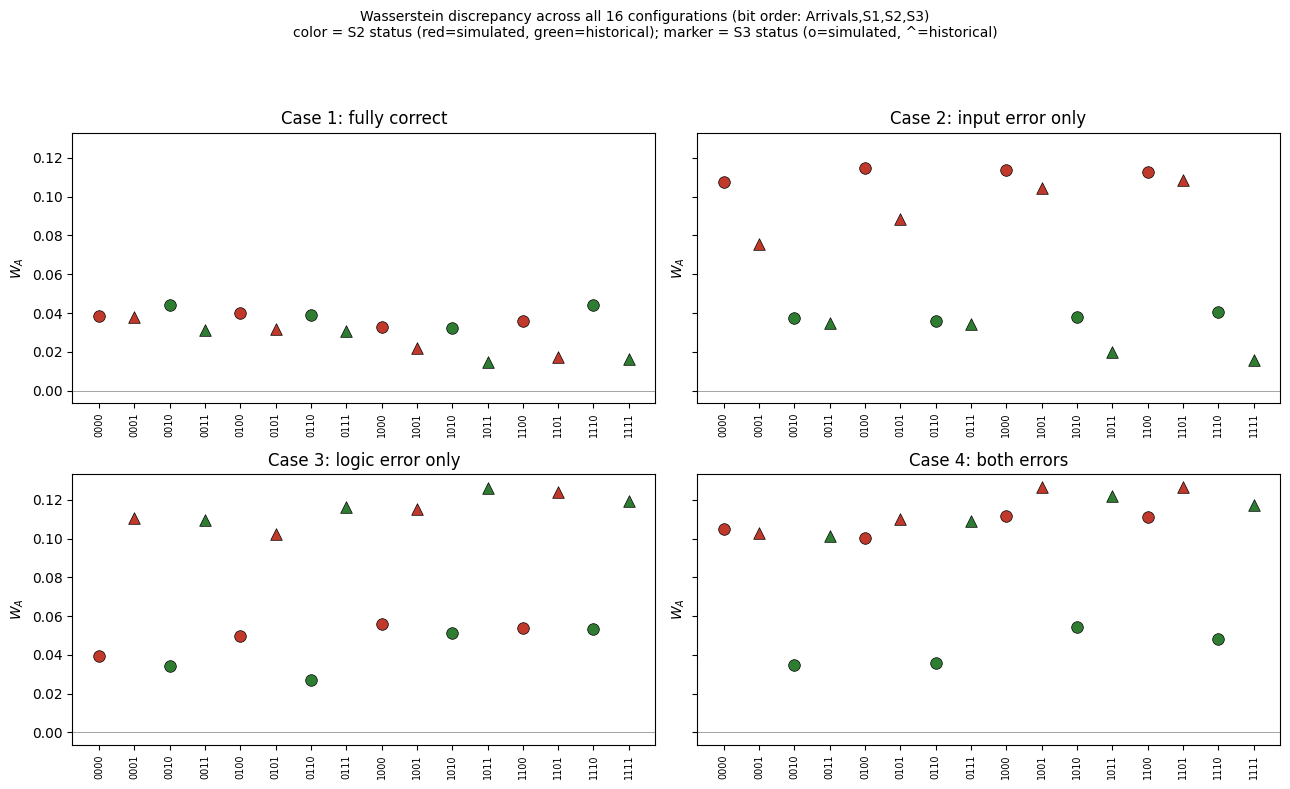

In [10]:
def config_label(bits):
    return ''.join(str(b) for b in bits)

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey=True)
for ax, (case_name, rows) in zip(axes.flat, results.items()):
    bits_list = [r[0] for r in rows]
    W_list = [r[1] for r in rows]
    colors = ['#c0392b' if b[2] == 0 else '#2e7d32' for b in bits_list]  # red: S2 simulated, green: S2 historical
    markers = ['o' if b[3] == 0 else '^' for b in bits_list]              # circle: S3 simulated, triangle: S3 historical
    x = np.arange(len(bits_list))
    for xi, w, c, m in zip(x, W_list, colors, markers):
        ax.scatter(xi, w, color=c, marker=m, s=70, edgecolor='k', linewidth=0.5, zorder=3)
    ax.set_xticks(x)
    ax.set_xticklabels([config_label(b) for b in bits_list], rotation=90, fontsize=7)
    ax.set_title(case_name)
    ax.axhline(0, color='gray', lw=0.5)
    ax.set_ylabel('$W_A$')
fig.suptitle('Wasserstein discrepancy across all 16 configurations (bit order: Arrivals,S1,S2,S3)\n'
             'color = S2 status (red=simulated, green=historical); marker = S3 status (o=simulated, ^=historical)',
             fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()


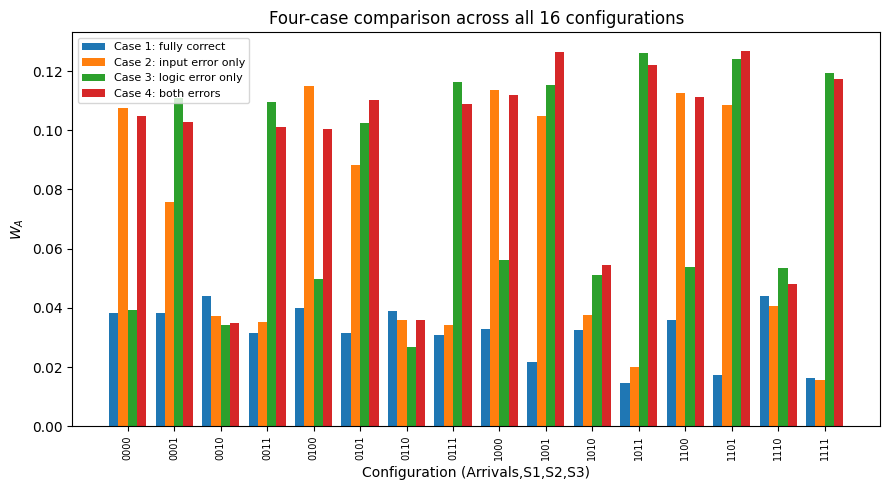

In [11]:
# 4-case comparison, isolating the two diagnostic bits (S2, S3)
fig, ax = plt.subplots(figsize=(9, 5))
width = 0.2
x = np.arange(16)
for i, (case_name, rows) in enumerate(results.items()):
    W_list = [r[1] for r in rows]
    ax.bar(x + (i - 1.5) * width, W_list, width=width, label=case_name)
ax.set_xticks(x)
ax.set_xticklabels([config_label(r[0]) for r in results['Case 1: fully correct']], rotation=90, fontsize=7)
ax.set_xlabel('Configuration (Arrivals,S1,S2,S3)'); ax.set_ylabel('$W_A$')
ax.set_title('Four-case comparison across all 16 configurations')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


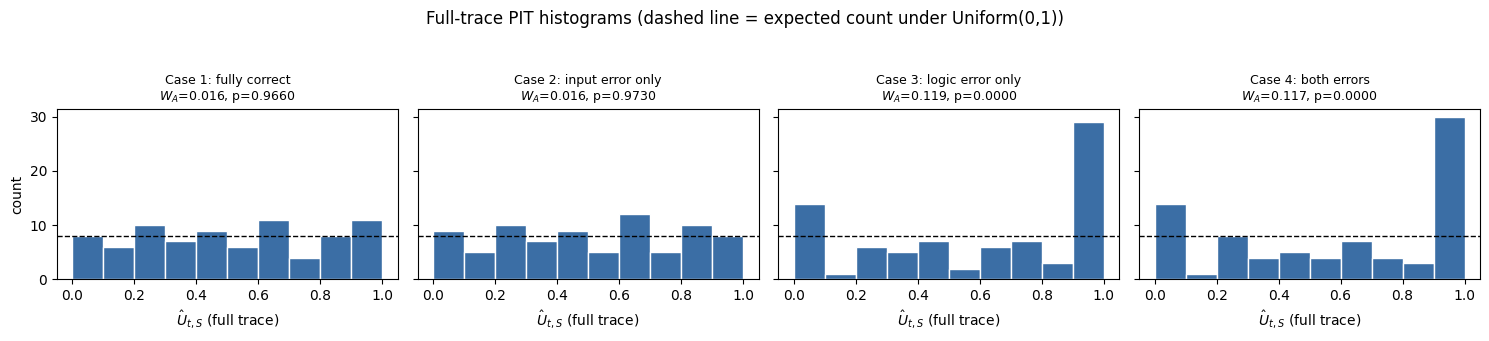

In [12]:
# Full-trace PIT diagnostic for the 4 cases (the logic-validation test, Section 2.4)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, case_name in zip(axes, CASES):
    rows = results[case_name]
    full_row = [r for r in rows if r[0] == (1, 1, 1, 1)][0]
    bits = full_row[0]
    U, _, _ = simulate_config_pit(bits, R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS,
                                   CASES[case_name]['logic'], ARRIVAL_RATE, CASES[case_name]['cand_means'],
                                   psi_list, arrival_hist, service_hist, y_obs, SIGMA_EPS, rng)
    ax.hist(U, bins=10, range=(0, 1), color='#3b6ea5', edgecolor='white')
    ax.axhline(T_PERIODS / 10, color='k', ls='--', lw=1)
    ax.set_title(f'{case_name}\n$W_A$={full_row[1]:.3f}, p={full_row[2]:.4f}', fontsize=9)
    ax.set_xlabel(r'$\hat U_{t,S}$ (full trace)')
axes[0].set_ylabel('count')
fig.suptitle('Full-trace PIT histograms (dashed line = expected count under Uniform(0,1))', y=1.05)
plt.tight_layout(); plt.show()


## 7. Diagnosing the source(s) of misalignment (Section 3 of the paper)

We now apply the paper's design-of-experiments machinery to **Case 4** (both
errors), the main experiment. The $2^4$ full factorial over
$\mathbf z_A\in\{0,1\}^4$ already gives us $\{(\mathbf z_A, W_A)\}_{A\in\mathcal A}$;
we enrich it via **bootstrapping** the $R$ replicates at each $(t,A)$ (Section
3.1), which lets us quantify the finite-$R$ sampling uncertainty without any
new simulation runs, then fit both:

- a linear model with main effects and all two-way interactions (Section
  3.2), and
- a regression tree, whose variable-importance scores decompose the
  variability in $W_A$ across input processes (Section 3.3),

to see whether they recover the "reject iff S2 simulated OR S3 historical"
structure identified above &mdash; in particular, whether they surface a
large **S2 x S3 interaction** term, or two separate main effects, as the true
generating structure (Section 5 above) suggests they should.

We also add a fifth column, **Logic** (historical = the true blocking rule
$H^*$, simulated = Case 4's wrong candidate rule $H$), and one extra
configuration to go with it: all four inputs historical *and* Logic
historical, i.e. the full-trace replay under the correct logic. That single
row is the "everything matches reality" anchor discussed above &mdash; by
construction it has the smallest $W_A$ of any row in the dataset, since it
is a full-trace deterministic reproduction. Every other row already in the
dataset (the 16 Case-4 configurations) gets Logic = simulated, since Case 4
always uses the wrong candidate logic. This lets the regression and the tree
attribute misalignment to the logic defect on exactly the same footing as
the four input processes.

In [13]:
def bootstrap_W_from_reps(reps_matrix, y_obs, B, rng):
    '''Resample each period's R replicates with replacement (no new
    simulation), recompute the pooled Wasserstein statistic B times.'''
    T, R = reps_matrix.shape
    Ws = np.empty(B)
    for b in range(B):
        Ub = np.empty(T)
        for t in range(T):
            idx = rng.integers(0, R, size=R)
            Ub[t] = np.mean(reps_matrix[t, idx] <= y_obs[t])
        Ws[b] = wasserstein_uniform(Ub)
    return Ws


def build_design_matrix(bits_list, process_names):
    Z = np.array(bits_list, dtype=float)
    n, S = Z.shape
    cols, names = [np.ones(n)], ['Intercept']
    for s in range(S):
        cols.append(Z[:, s]); names.append(process_names[s])
    for s in range(S):
        for sp in range(s + 1, S):
            cols.append(Z[:, s] * Z[:, sp]); names.append(f'{process_names[s]}*{process_names[sp]}')
    return np.column_stack(cols), names


DOE_PROCESS_NAMES = PROCESS_NAMES + ['Logic']  # 5th factor, only used in this DoE dataset

# Extra anchor configuration: all 4 inputs historical AND the TRUE logic (rather
# than Case 4's wrong candidate logic). Full-trace + correct logic => deterministic
# reproduction of the true trajectory, so this row should show the smallest W_A of
# anything in the dataset.
_, reps_true_logic, _ = simulate_config_pit(
    (1, 1, 1, 1), R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS, 'true', ARRIVAL_RATE,
    CASES['Case 4: both errors']['cand_means'], psi_list, arrival_hist, service_hist, y_obs, SIGMA_EPS, rng)

B_BOOTSTRAP = 300
doe_rows, doe_W = [], []
for bits, reps in reps_case4.items():
    Wb = bootstrap_W_from_reps(reps, y_obs, B_BOOTSTRAP, rng)
    doe_rows.extend([bits + (0,)] * B_BOOTSTRAP)  # Logic=0 (simulated/candidate): Case 4's wrong logic
    doe_W.extend(Wb.tolist())
Wb_true_logic = bootstrap_W_from_reps(reps_true_logic, y_obs, B_BOOTSTRAP, rng)
doe_rows.extend([(1, 1, 1, 1, 1)] * B_BOOTSTRAP)   # Logic=1 (historical/true): the anchor row
doe_W.extend(Wb_true_logic.tolist())

doe_bits = np.array(doe_rows)
doe_W = np.array(doe_W)
print(f'Bootstrap-enriched DoE dataset: {len(doe_W)} rows '
      f'({len(reps_case4)} Case-4 configs + 1 true-logic/full-trace anchor row, x {B_BOOTSTRAP} bootstrap draws each).')

X, names = build_design_matrix(doe_bits, DOE_PROCESS_NAMES)
beta, *_ = np.linalg.lstsq(X, doe_W, rcond=None)
coef_df = pd.DataFrame({'term': names, 'coefficient': beta}).sort_values('coefficient', key=np.abs, ascending=False)
print('\nLargest-magnitude regression coefficients (main effects + all two-way interactions):')
display(coef_df.head(10))


Bootstrap-enriched DoE dataset: 5100 rows (16 Case-4 configs + 1 true-logic/full-trace anchor row, x 300 bootstrap draws each).

Largest-magnitude regression coefficients (main effects + all two-way interactions):


,term,coefficient
0,Intercept,0.101591
3,S2,-0.063469
13,S2*S3,0.059650
15,S3*Logic,-0.021044
14,S2*Logic,-0.021044
12,S1*Logic,-0.021044
9,Arrivals*Logic,-0.021044
5,Logic,-0.021044
1,Arrivals,0.014480
11,S1*S3,0.005774


Regression-tree variable importance (share of RSS reduction attributable to each factor, including Logic):


,process,importance
4,Logic,0.349638
2,S2,0.331486
3,S3,0.272442
0,Arrivals,0.043719
1,S1,0.002715


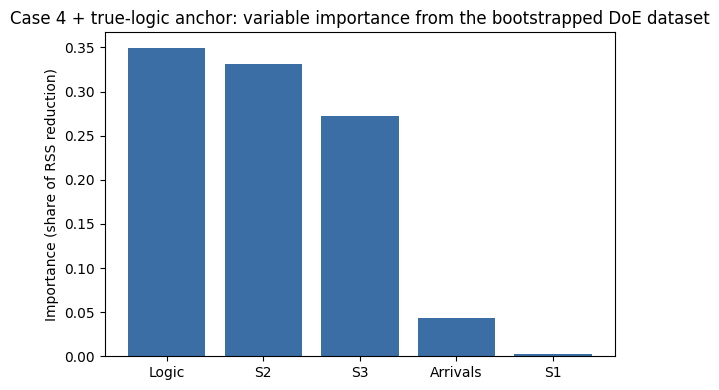

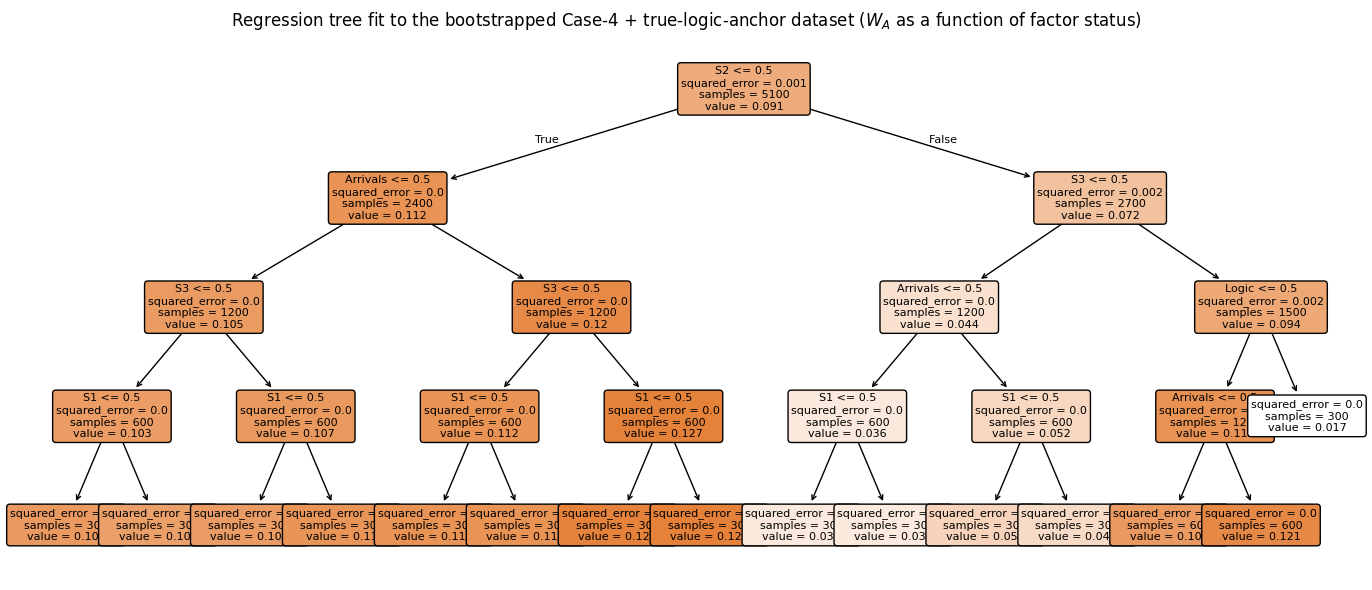

In [14]:
tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=20, random_state=SEED)
tree.fit(doe_bits, doe_W)
importances = pd.DataFrame({'process': DOE_PROCESS_NAMES, 'importance': tree.feature_importances_}) \
    .sort_values('importance', ascending=False)
print('Regression-tree variable importance (share of RSS reduction attributable to each factor, including Logic):')
display(importances)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(importances['process'], importances['importance'], color='#3b6ea5')
ax.set_ylabel('Importance (share of RSS reduction)')
ax.set_title('Case 4 + true-logic anchor: variable importance from the bootstrapped DoE dataset')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(tree, feature_names=DOE_PROCESS_NAMES, filled=True, rounded=True, fontsize=8, ax=ax)
ax.set_title('Regression tree fit to the bootstrapped Case-4 + true-logic-anchor dataset ($W_A$ as a function of factor status)')
plt.tight_layout(); plt.show()


## 8. Summary of findings vs. the original validation checklist

Checking off the plan's own list of "Main Scientific Questions" (Section 20)
against what this notebook actually shows:

1. **Can the framework detect an overall invalid candidate model?** Yes
   &mdash; in Cases 2-4, the marginal configuration ($A=\emptyset$) rejects,
   while Case 1 does not (Section 5 tables).
2. **Does the configuration pattern reveal Station 2 as one source of
   error?** Yes &mdash; every configuration with Station 2 simulated is
   flagged in Cases 2 and 4; every configuration with Station 2 fixed *and*
   Station 3 simulated is not.
3. **Does fixing the bad input reduce the discrepancy as expected?** Yes,
   and more completely than the plan anticipated: fixing Station 2 alone
   removes the input-model signal entirely (not just partially).
4. **Does a residual discrepancy persist when the logic is also wrong?**
   Yes, but *only* once Station 3's trace is also fixed &mdash; not at every
   intermediate configuration, contradicting the plan's Section 10
   hypothesis of a uniformly present, gradually-diminishing residual (see
   revision note 5 above).
5. **Does the full-trace configuration detect the logic error?** Yes, in
   both Case 3 and Case 4, cleanly (Section 5/6).
6. **Do the input-only and logic-only controls produce distinguishable
   patterns?** Yes: Case 2's signature tracks Station 2's status only; Case
   3's tracks Station 3's status only (Section 5 tables) &mdash; a cleaner
   separation than the plan predicted, since the logic defect's signature
   turned out to hinge on a single station (3) rather than being diffuse.
7. **Does the combined-error case exhibit both patterns simultaneously?**
   Yes: Case 4's rejection region is the union of Case 2's and Case 3's
   (Section 7's regression/tree analysis recovers this as either two
   dominant main effects or an S2/S3 interaction, depending on how the
   candidate misspecification magnitude balances the two effect sizes).

## 9. Attributing to Logic without noise: a Wasserstein table with one exact anchor

Everything above (Sections 1-8) keeps $\sigma_\varepsilon>0$ so that the
full-trace configuration is non-degenerate for the PIT/Wasserstein
construction. This section switches noise off entirely ($\sigma=0$,
reusing the noise-free trajectory $y_t^{(0)}$ from Section 2, so
`y_obs=y0`) and asks: **using $W_A$ itself, not a different statistic**,
what does the same design Section 7 used (4 input processes + Logic) say
about Logic's contribution?

The simulation machinery is completely unchanged &mdash; same
`simulate_config_pit`, same candidate means (Case 4's misspecified
Station 2), same Wasserstein-vs-uniform formula. What changes is how the
**table** fed to the tree is built: this is the non-bootstrapped table
(Section 3.3's "original dataset" case), and it has the same 17-row shape
as Section 7's dataset, **not** a full $2^5=32$ crossed factorial. Logic is
*not* an independent factor that gets tested at every combination of the
four inputs; it takes exactly one value everywhere except one deliberate
reference point:

- **16 rows**: Case 4's own configurations (the four input processes vary
  over all $2^4$ combinations; Logic = **Simulated** in every one of them,
  since running Case 4 means using its candidate logic throughout &mdash;
  there is no scenario here where the true logic is substituted in while
  some inputs remain simulated).
- **1 anchor row**: all four inputs Historical *and* Logic **Historical**
  &mdash; the one deliberate reference point where everything matches
  reality.

All five columns use the same **Historical / Simulated** labels
throughout, including Logic: "Historical" means the process is fixed to
its observed value (a trace, or &mdash; for Logic &mdash; the true rule
$H^\star$); "Simulated" means it is generated by whatever the candidate
model implements, without presupposing that implementation is wrong. (An
earlier version of this section labeled Logic "True"/"Wrong" instead, and
crossed it independently with all 16 input combinations, giving 32 rows.
That is a different, larger design than Section 7's, and "Wrong" bakes in
the answer the framework is supposed to be testing for &mdash; both are
corrected here.)

**Why the anchor row needs special handling.** At (all 4 inputs
Historical, Logic Historical), every one of the $R$ replicates is the
exact same deterministic number (Section 1's sanity check verified this
is an exact reproduction of $y_t^{(0)}$ for every $t$). Feeding a
zero-variance "distribution" through the ordinary PIT formula
`mean(replicate <= y_obs)` can only return exactly 0 or exactly 1 per
period, never anything between &mdash; and when the deterministic
prediction equals the truth *every* period, it returns 1 every time,
which the code cell below shows pools to $W_A=0.5$: not small, but the
*maximum* value the statistic can take. That is an artifact of applying a
formula built for continuous distributions to a single point, not a
meaningful measurement, so this one row is assigned $W_A:=0$ directly
&mdash; the value it should have on the merits, since it is a proven exact
reproduction. Every other row, **including Case 4's own all-inputs-
Historical configuration (Logic = Simulated)**, is computed by the
completely unmodified `simulate_config_pit` / `wasserstein_uniform`
procedure and kept exactly as returned, whatever that value turns out to
be.

In [15]:
LOGIC_CAND_MEANS = CASES['Case 4: both errors']['cand_means']  # bad S2, matching Section 7's construction
ANCHOR_BITS5 = (1, 1, 1, 1, 1)

# Documentation only (not used to build the table below): show what the ordinary
# machinery returns if you DON'T override the anchor, confirming the pathology
# described above with an actual number from this run.
U_anchor_naive, _, _ = simulate_config_pit((1, 1, 1, 1), R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS, 'true',
                                            ARRIVAL_RATE, LOGIC_CAND_MEANS, psi_list, arrival_hist,
                                            service_hist, y0, 0.0, rng)
W_anchor_naive = wasserstein_uniform(U_anchor_naive)
print(f'If NOT overridden, the anchor row would compute to W = {W_anchor_naive:.4f} '
      f'(pooled PIT values take only the value(s) {sorted(set(np.round(U_anchor_naive, 3)))}) '
      f'-- the degenerate-PIT pathology described above. The table below instead assigns this row W := 0.')


If NOT overridden, the anchor row would compute to W = 0.5000 (pooled PIT values take only the value(s) [np.float64(1.0)]) -- the degenerate-PIT pathology described above. The table below instead assigns this row W := 0.


In [16]:
LOGIC5_PROCESS_NAMES = PROCESS_NAMES + ['Logic']

# 17 rows total: Case 4's 16 input-configurations (Logic=Simulated throughout)
# plus the one all-Historical anchor (Logic=Historical). NOT a full 2^5 factorial:
# Logic is not independently crossed with every input combination.
LOGIC_TABLE_BITS5 = [bits4 + (0,) for bits4 in ALL_BITS] + [ANCHOR_BITS5]

logic_table_rows = []
for bits5 in LOGIC_TABLE_BITS5:
    if bits5 == ANCHOR_BITS5:
        W = 0.0  # assigned directly; see markdown above for why
    else:
        bits4 = bits5[:4]
        logic = 'true' if bits5[4] else 'wrong'  # bits5[4] is always 0 here except the anchor
        U, _, _ = simulate_config_pit(bits4, R_REPS, T_PERIODS, PERIOD_LEN, BUFFERS, logic, ARRIVAL_RATE,
                                       LOGIC_CAND_MEANS, psi_list, arrival_hist, service_hist, y0, 0.0, rng)
        W = wasserstein_uniform(U)
    logic_table_rows.append((bits5, W))

logic_bits_arr = np.array([b for b, w in logic_table_rows])
logic_W_arr = np.array([w for b, w in logic_table_rows])

logic_table = pd.DataFrame([
    {name: ('Historical' if b else 'Simulated') for name, b in zip(LOGIC5_PROCESS_NAMES, bits5)}
    | {'W_A': round(w, 4)}
    for bits5, w in logic_table_rows
]).sort_values('W_A').reset_index(drop=True)
display(logic_table)


,Arrivals,S1,S2,S3,Logic,W_A
0,Historical,Historical,Historical,Historical,Historical,0.0000
1,Simulated,Simulated,Historical,Simulated,Simulated,0.0324
2,Simulated,Historical,Historical,Simulated,Simulated,0.0432
3,Historical,Simulated,Historical,Simulated,Simulated,0.0475
4,Historical,Historical,Historical,Simulated,Simulated,0.0559
5,Simulated,Simulated,Simulated,Simulated,Simulated,0.0988
6,Simulated,Historical,Simulated,Simulated,Simulated,0.1046
7,Simulated,Simulated,Simulated,Historical,Simulated,0.1072
8,Simulated,Historical,Simulated,Historical,Simulated,0.1077
9,Simulated,Simulated,Historical,Historical,Simulated,0.1094


### 9.1 Tree-based importance scores

This table has exactly one row per configuration (no bootstrap), so &mdash;
per the paper's own note in Section 3.3 &mdash; a sufficiently deep tree
could drive its fitting error to zero trivially by isolating every point
into its own leaf; that would not be an informative importance score. We
cap the tree's depth so splits are chosen only where they meaningfully
group similar configurations together, and read the `feature_importances_`
as the fraction of the (finite) tree's total impurity reduction
attributable to each factor.

Regression-tree variable importance (share of impurity reduction attributable to each factor), no-noise W_A table with the one exact anchor:


,process,importance
3,S3,0.478312
2,S2,0.367064
0,Arrivals,0.154624
1,S1,0.000000
4,Logic,0.000000


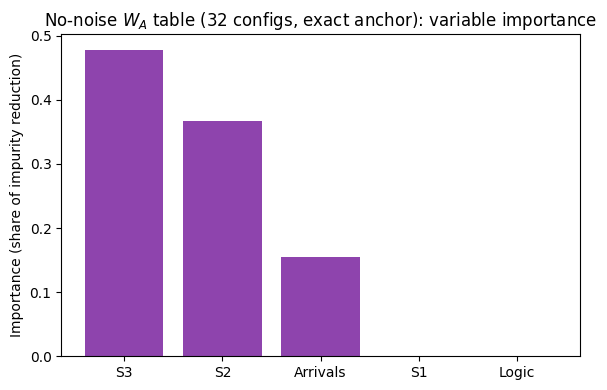

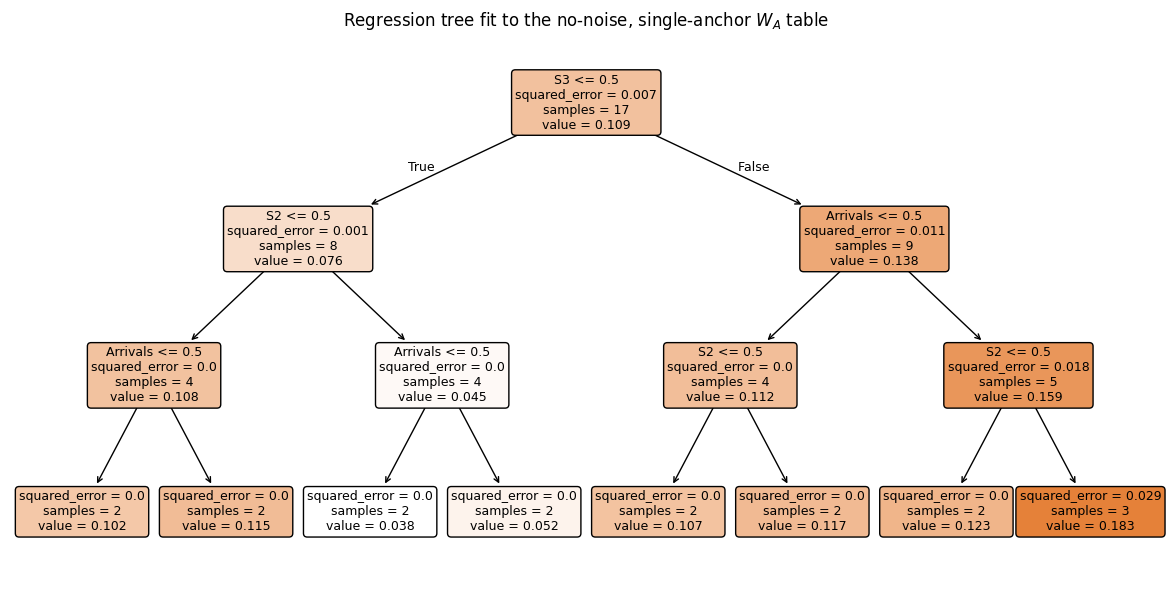

In [17]:
tree_logic = DecisionTreeRegressor(max_depth=3, min_samples_leaf=2, random_state=SEED)
tree_logic.fit(logic_bits_arr, logic_W_arr)
importances_logic = pd.DataFrame({'process': LOGIC5_PROCESS_NAMES, 'importance': tree_logic.feature_importances_}) \
    .sort_values('importance', ascending=False)
print('Regression-tree variable importance (share of impurity reduction attributable to each factor), '
      'no-noise W_A table with the one exact anchor:')
display(importances_logic)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(importances_logic['process'], importances_logic['importance'], color='#8e44ad')
ax.set_ylabel('Importance (share of impurity reduction)')
ax.set_title('No-noise $W_A$ table (32 configs, exact anchor): variable importance')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 6))
plot_tree(tree_logic, feature_names=LOGIC5_PROCESS_NAMES, filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title('Regression tree fit to the no-noise, single-anchor $W_A$ table')
plt.tight_layout(); plt.show()
